# DỰ ÁN PHÂN TÍCH VÀ TIỀN XỬ LÝ DỮ LIỆU ĐIỆN THOẠI
**Quy trình chuẩn hóa: Khám phá Dữ liệu (EDA) -> Phân chia Tập dữ liệu (Train/Val/Test) -> Tiền xử lý & Trích xuất Đặc trưng**

### Khai báo thư viện và Cấu hình hiển thị biểu đồ

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Thiết lập hiển thị cho biểu đồ
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

### Đọc dữ liệu vào Pandas DataFrame
Hỗ trợ cả môi trường Google Colab và Jupyter Notebook chạy trên máy tính cục bộ.

In [2]:
file_path = 'phone_dataset_cleaned.csv'

# Kiểm tra nếu chạy trên Google Colab và file chưa có thì cho phép upload
if not os.path.exists(file_path):
    try:
        from google.colab import files
        print("Đang chạy trên Google Colab. Vui lòng chọn tải file lên:")
        uploaded = files.upload()
        file_path = list(uploaded.keys())[0]
    except ImportError:
        # Đường dẫn dự phòng trên máy tính cục bộ
        file_path = r'D:\File Code\Testing model\phone_dataset_cleaned.csv'

df_raw = pd.read_csv(file_path)
df = df_raw.copy()
print(f"Đã tải thành công dữ liệu: {df.shape[0]} dòng và {df.shape[1]} cột.")
display(df.head())

Đã tải thành công dữ liệu: 1910 dòng và 21 cột.


,Hãng Sản Xuất,Giá Bán (EUR),RAM (GB),ROM (GB),Kích Thước Màn Hình (inch),Tỷ Lệ Màn Hình (%),Tấm Nền Màn Hình,Camera Sau (MP),Camera Trước (MP),Dung Lượng Pin (mAh),Thiết Kế Pin,Độ Dày (mm),Trọng Lượng (g),Cảm Biến Vân Tay,Hỗ Trợ Mạng,Hãng Chip,Số Nhân CPU (Core),Xung Nhịp CPU (GHz),Năm Ra Mắt,NFC_Clean,Độ Phân Giải Đường Chéo (Pixels)
0,Acer,170.0,2.0,32.0,7.0,69.8,IPS LCD,13.0,2.0,3400.0,Nguyên khối,9.4,260.0,Không,4G / LTE,MediaTek,4.0,1.30,2016.0,0,1468.60478
1,Acer,250.0,3.0,32.0,5.5,71.7,IPS LCD,13.0,5.0,4080.0,Tháo rời,8.5,169.0,Có,4G / LTE,MediaTek,8.0,1.30,2016.0,0,2202.90717
2,Acer,120.0,1.0,8.0,5.0,NaN,IPS LCD,8.0,2.0,2000.0,Tháo rời,NaN,NaN,Không,4G / LTE,MediaTek,4.0,1.25,2016.0,0,1468.60478
3,Acer,230.0,3.0,32.0,5.5,69.0,IPS LCD,13.0,13.0,4020.0,Tháo rời,8.5,166.0,Không,4G / LTE,MediaTek,8.0,1.30,2015.0,0,1468.60478
4,Acer,200.0,2.0,16.0,5.5,70.3,IPS LCD,13.0,5.0,5000.0,Nguyên khối,10.0,NaN,Không,4G / LTE,MediaTek,4.0,1.30,2016.0,0,1468.60478


## PHẦN I: KHÁM PHÁ VÀ TRỰC QUAN HÓA DỮ LIỆU (EDA)
Trong phần này, chúng ta sẽ xem xét cấu trúc tổng quan của bộ dữ liệu, phân tích các giá trị thiếu, phân phối của các biến và mối quan hệ giữa các đặc trưng kỹ thuật với giá bán để tìm insight.

### 1. Phân tích Thông tin cơ bản (EDA Sơ bộ)
Chúng ta sẽ xem xét cấu trúc tổng quan của bộ dữ liệu bao gồm số lượng dòng, cột, kiểu dữ liệu và số lượng giá trị thiếu (null).

In [3]:
print("--- Thông tin cấu trúc dữ liệu ---")
df.info()

print("\n--- Thống kê mô tả (Numeric) ---")
display(df.describe())

print("\n--- Số lượng giá trị thiếu (Missing Values) ---")
missing_counts = df.isnull().sum()
display(missing_counts[missing_counts > 0])

--- Thông tin cấu trúc dữ liệu ---
<class 'pandas.DataFrame'>
RangeIndex: 1910 entries, 0 to 1909
Data columns (total 21 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hãng Sản Xuất                     1910 non-null   str    
 1   Giá Bán (EUR)                     1910 non-null   float64
 2   RAM (GB)                          1792 non-null   float64
 3   ROM (GB)                          1838 non-null   float64
 4   Kích Thước Màn Hình (inch)        1905 non-null   float64
 5   Tỷ Lệ Màn Hình (%)                1832 non-null   float64
 6   Tấm Nền Màn Hình                  1762 non-null   str    
 7   Camera Sau (MP)                   1908 non-null   float64
 8   Camera Trước (MP)                 1861 non-null   float64
 9   Dung Lượng Pin (mAh)              1872 non-null   float64
 10  Thiết Kế Pin                      1910 non-null   str    
 11  Độ Dày (mm)                       1824 non-nu

,Giá Bán (EUR),RAM (GB),ROM (GB),Kích Thước Màn Hình (inch),Tỷ Lệ Màn Hình (%),Camera Sau (MP),Camera Trước (MP),Dung Lượng Pin (mAh),Độ Dày (mm),Trọng Lượng (g),Số Nhân CPU (Core),Xung Nhịp CPU (GHz),Năm Ra Mắt,NFC_Clean,Độ Phân Giải Đường Chéo (Pixels)
count,1910.000000,1792.000000,1838.000000,1905.000000,1832.000000,1908.000000,1861.000000,1872.000000,1824.000000,1690.000000,1885.000000,1877.000000,1909.000000,1910.000000,1905.000000
mean,232.712042,1.845982,22.395158,5.041349,66.464902,9.963077,3.775819,2562.146902,9.069298,157.958047,4.597878,1.488535,2014.257203,0.325654,1567.227069
std,136.686738,1.054884,27.027405,0.769781,6.529763,4.431226,3.403404,801.568976,1.689658,44.248241,2.271534,0.397166,1.643983,0.468742,571.973137
min,40.000000,1.000000,1.000000,3.000000,22.800000,0.300000,0.000000,1000.000000,4.900000,88.200000,1.000000,0.260000,2007.000000,0.000000,400.000000
25%,140.000000,1.000000,8.000000,4.500000,63.675000,8.000000,1.300000,2000.000000,7.900000,135.000000,4.000000,1.200000,2013.000000,0.000000,1101.453585
50%,200.000000,1.500000,16.000000,5.000000,67.400000,8.000000,2.000000,2460.000000,8.900000,149.000000,4.000000,1.400000,2014.000000,0.000000,1468.604780
75%,280.000000,2.000000,32.000000,5.500000,70.800000,13.000000,5.000000,3000.000000,9.900000,167.000000,8.000000,1.700000,2016.000000,1.000000,2202.907170
max,1400.000000,8.000000,256.000000,8.000000,93.200000,41.000000,20.000000,7000.000000,21.100000,480.000000,10.000000,2.700000,2017.000000,1.000000,4405.814340


RAM (GB)                            118
ROM (GB)                             72
Kích Thước Màn Hình (inch)            5
Tỷ Lệ Màn Hình (%)                   78
Tấm Nền Màn Hình                    148
Camera Sau (MP)                       2
Camera Trước (MP)                    49
Dung Lượng Pin (mAh)                 38
Độ Dày (mm)                          86
Trọng Lượng (g)                     220
Hãng Chip                           226
Số Nhân CPU (Core)                   25
Xung Nhịp CPU (GHz)                  33
Năm Ra Mắt                            1
Độ Phân Giải Đường Chéo (Pixels)      5
dtype: int64

### 2. Trực quan hóa Phân phối của các cột có giá trị thiếu (Missing Values)
Chúng ta sẽ vẽ biểu đồ để kiểm tra phân phối của các thuộc tính bị khuyết thiếu:
- **Biểu đồ phân phối (Histogram/KDE)** cho các thuộc tính số có giá trị khuyết thiếu.
- **Biểu đồ cột (Countplot)** cho các thuộc tính phân loại (categorical): `Tấm Nền Màn Hình`, `Hãng Chip`.

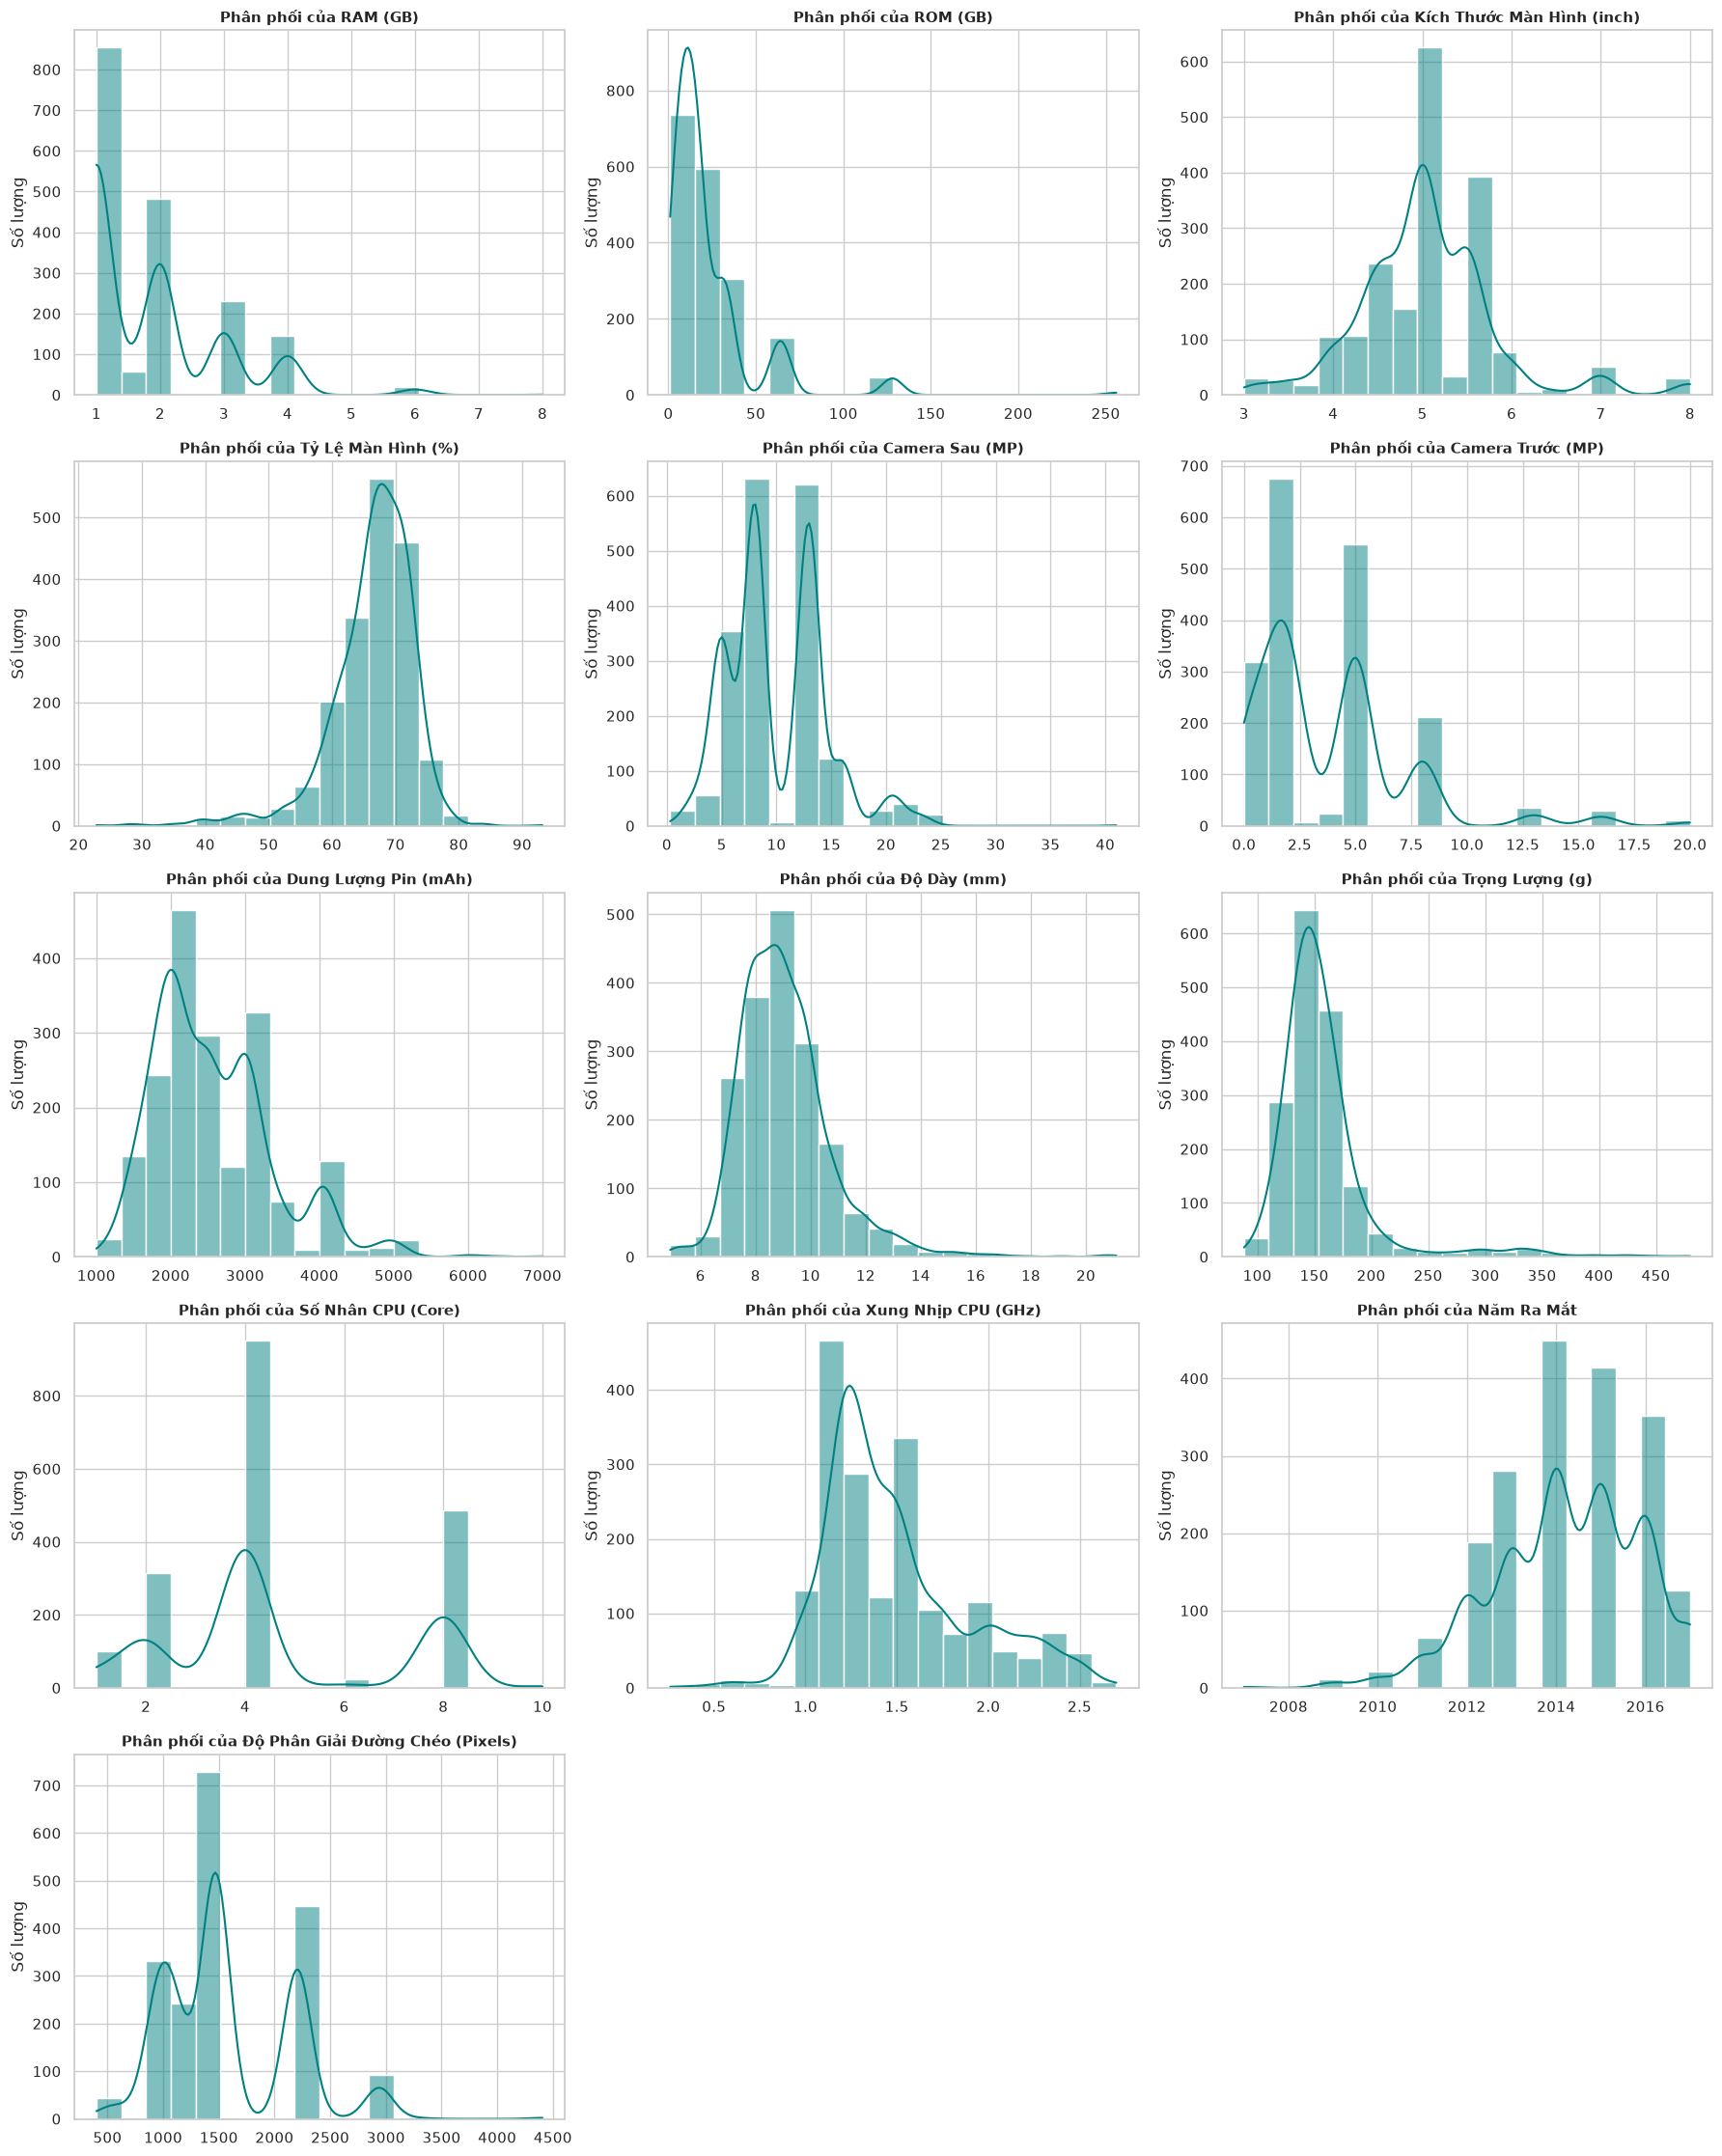

In [4]:
# 1. Vẽ phân phối cho các cột dạng số có missing values
numeric_cols_with_nan = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if df[col].isnull().sum() > 0
]

n_cols = 3
n_rows = int(np.ceil(len(numeric_cols_with_nan) / n_cols))
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(18, 4.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols_with_nan):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='teal', bins=18)
    axes[i].set_title(f'Phân phối của {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Số lượng')

for j in range(len(numeric_cols_with_nan), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

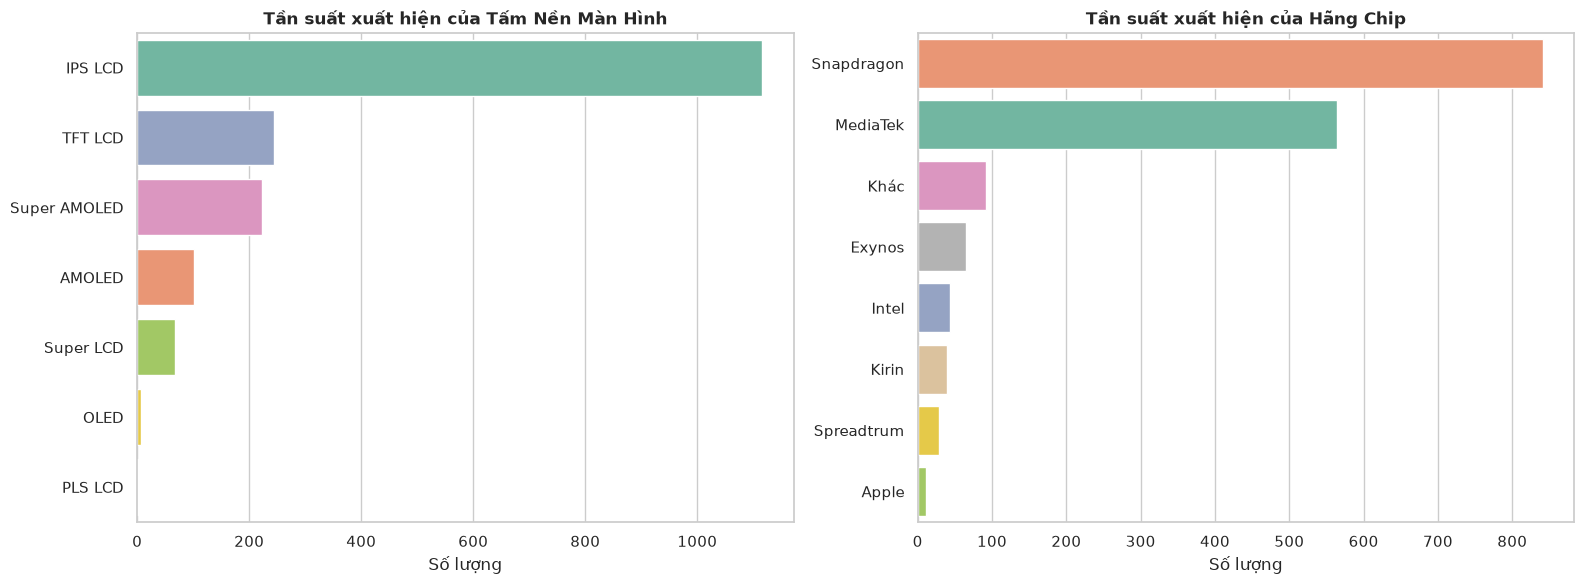

In [5]:
# 2. Vẽ phân phối cho các cột phân loại (Categorical) có missing values
categorical_cols_with_nan = [
    'Tấm Nền Màn Hình',
    'Hãng Chip'
]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

for i, col in enumerate(categorical_cols_with_nan):
    order = df[col].value_counts().index
    sns.countplot(
        data=df,
        y=col,
        ax=axes[i],
        order=order,
        palette='Set2',
        hue=col,
        legend=False
    )
    axes[i].set_title(f'Tần suất xuất hiện của {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Số lượng')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

### 3. Phân tích Phân phối Giá Bán (Biến Mục Tiêu)
Tiếp đến em sẽ vẽ biểu đồ phân phối giá để kiểm tra độ lệch (skewness) và xem xét việc áp dụng biến đổi log (log-transform).

Độ lệch của Giá Bán ban đầu: 1.99 (Lệch phải nhiều do tập trung máy tầm trung/phổ thông và ít máy cao cấp)
Độ lệch sau khi áp dụng log-transform: 0.12 (Phân phối chuẩn hóa đối xứng và cân bằng hơn rất nhiều)


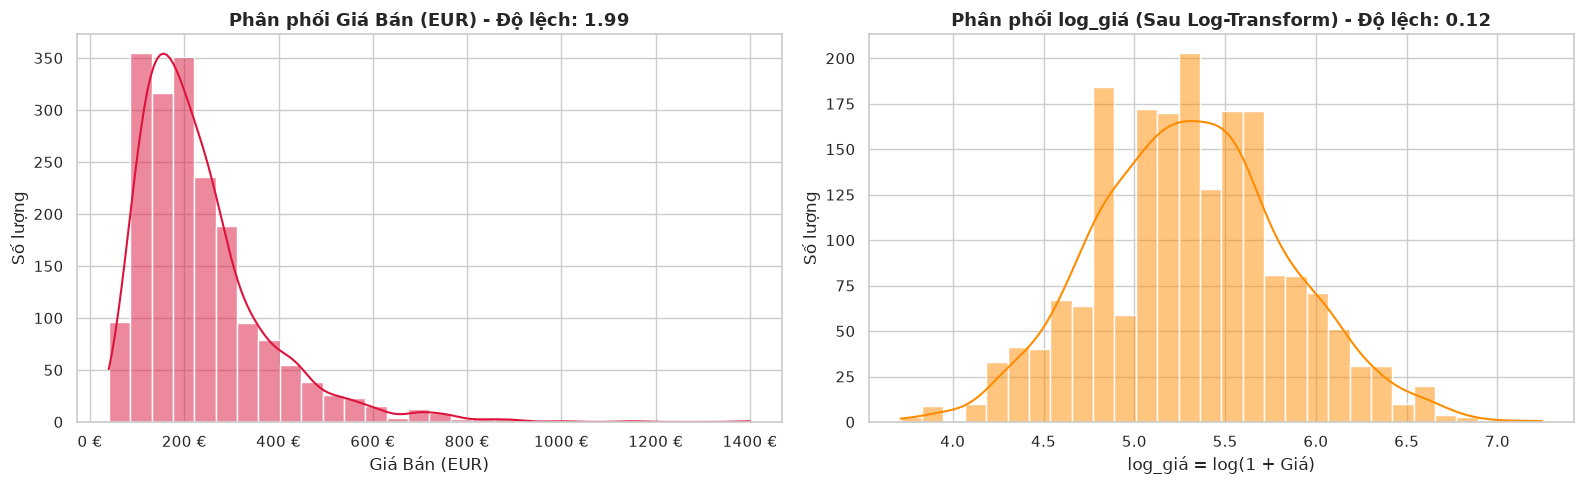

In [6]:
from matplotlib.ticker import FuncFormatter

# Kiểm tra phân phối giá gốc và sau khi log-transform
log_gia_eda = np.log1p(df['Giá Bán (EUR)'])
price_skew = df['Giá Bán (EUR)'].skew()
log_price_skew = log_gia_eda.skew()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

# 1. Phân phối Giá gốc
sns.histplot(data=df, x='Giá Bán (EUR)', kde=True, color='crimson', bins=30, ax=axes[0])
axes[0].set_title(f'Phân phối Giá Bán (EUR) - Độ lệch: {price_skew:.2f}', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Giá Bán (EUR)')
axes[0].set_ylabel('Số lượng')
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0f} €'))

# 2. Phân phối sau log-transform
sns.histplot(x=log_gia_eda, kde=True, color='darkorange', bins=30, ax=axes[1])
axes[1].set_title(f'Phân phối log_giá (Sau Log-Transform) - Độ lệch: {log_price_skew:.2f}', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log_giá = log(1 + Giá)')
axes[1].set_ylabel('Số lượng')

plt.tight_layout()
plt.show()

print(f"Độ lệch của Giá Bán ban đầu: {price_skew:.2f} (Lệch phải nhiều do tập trung máy tầm trung/phổ thông và ít máy cao cấp)")
print(f"Độ lệch sau khi áp dụng log-transform: {log_price_skew:.2f} (Phân phối chuẩn hóa đối xứng và cân bằng hơn rất nhiều)")

### 4. Mối tương quan giữa log_giá và các thông số kỹ thuật cốt lõi
Khởi tạo khung lưới biểu đồ mối quan hệ giữa `log_giá` và các thông số chính để tìm insight: Hãng sản xuất (Top 15 hãng phổ biến nhất), RAM, ROM, Camera sau, Số nhân CPU và Dung lượng pin.

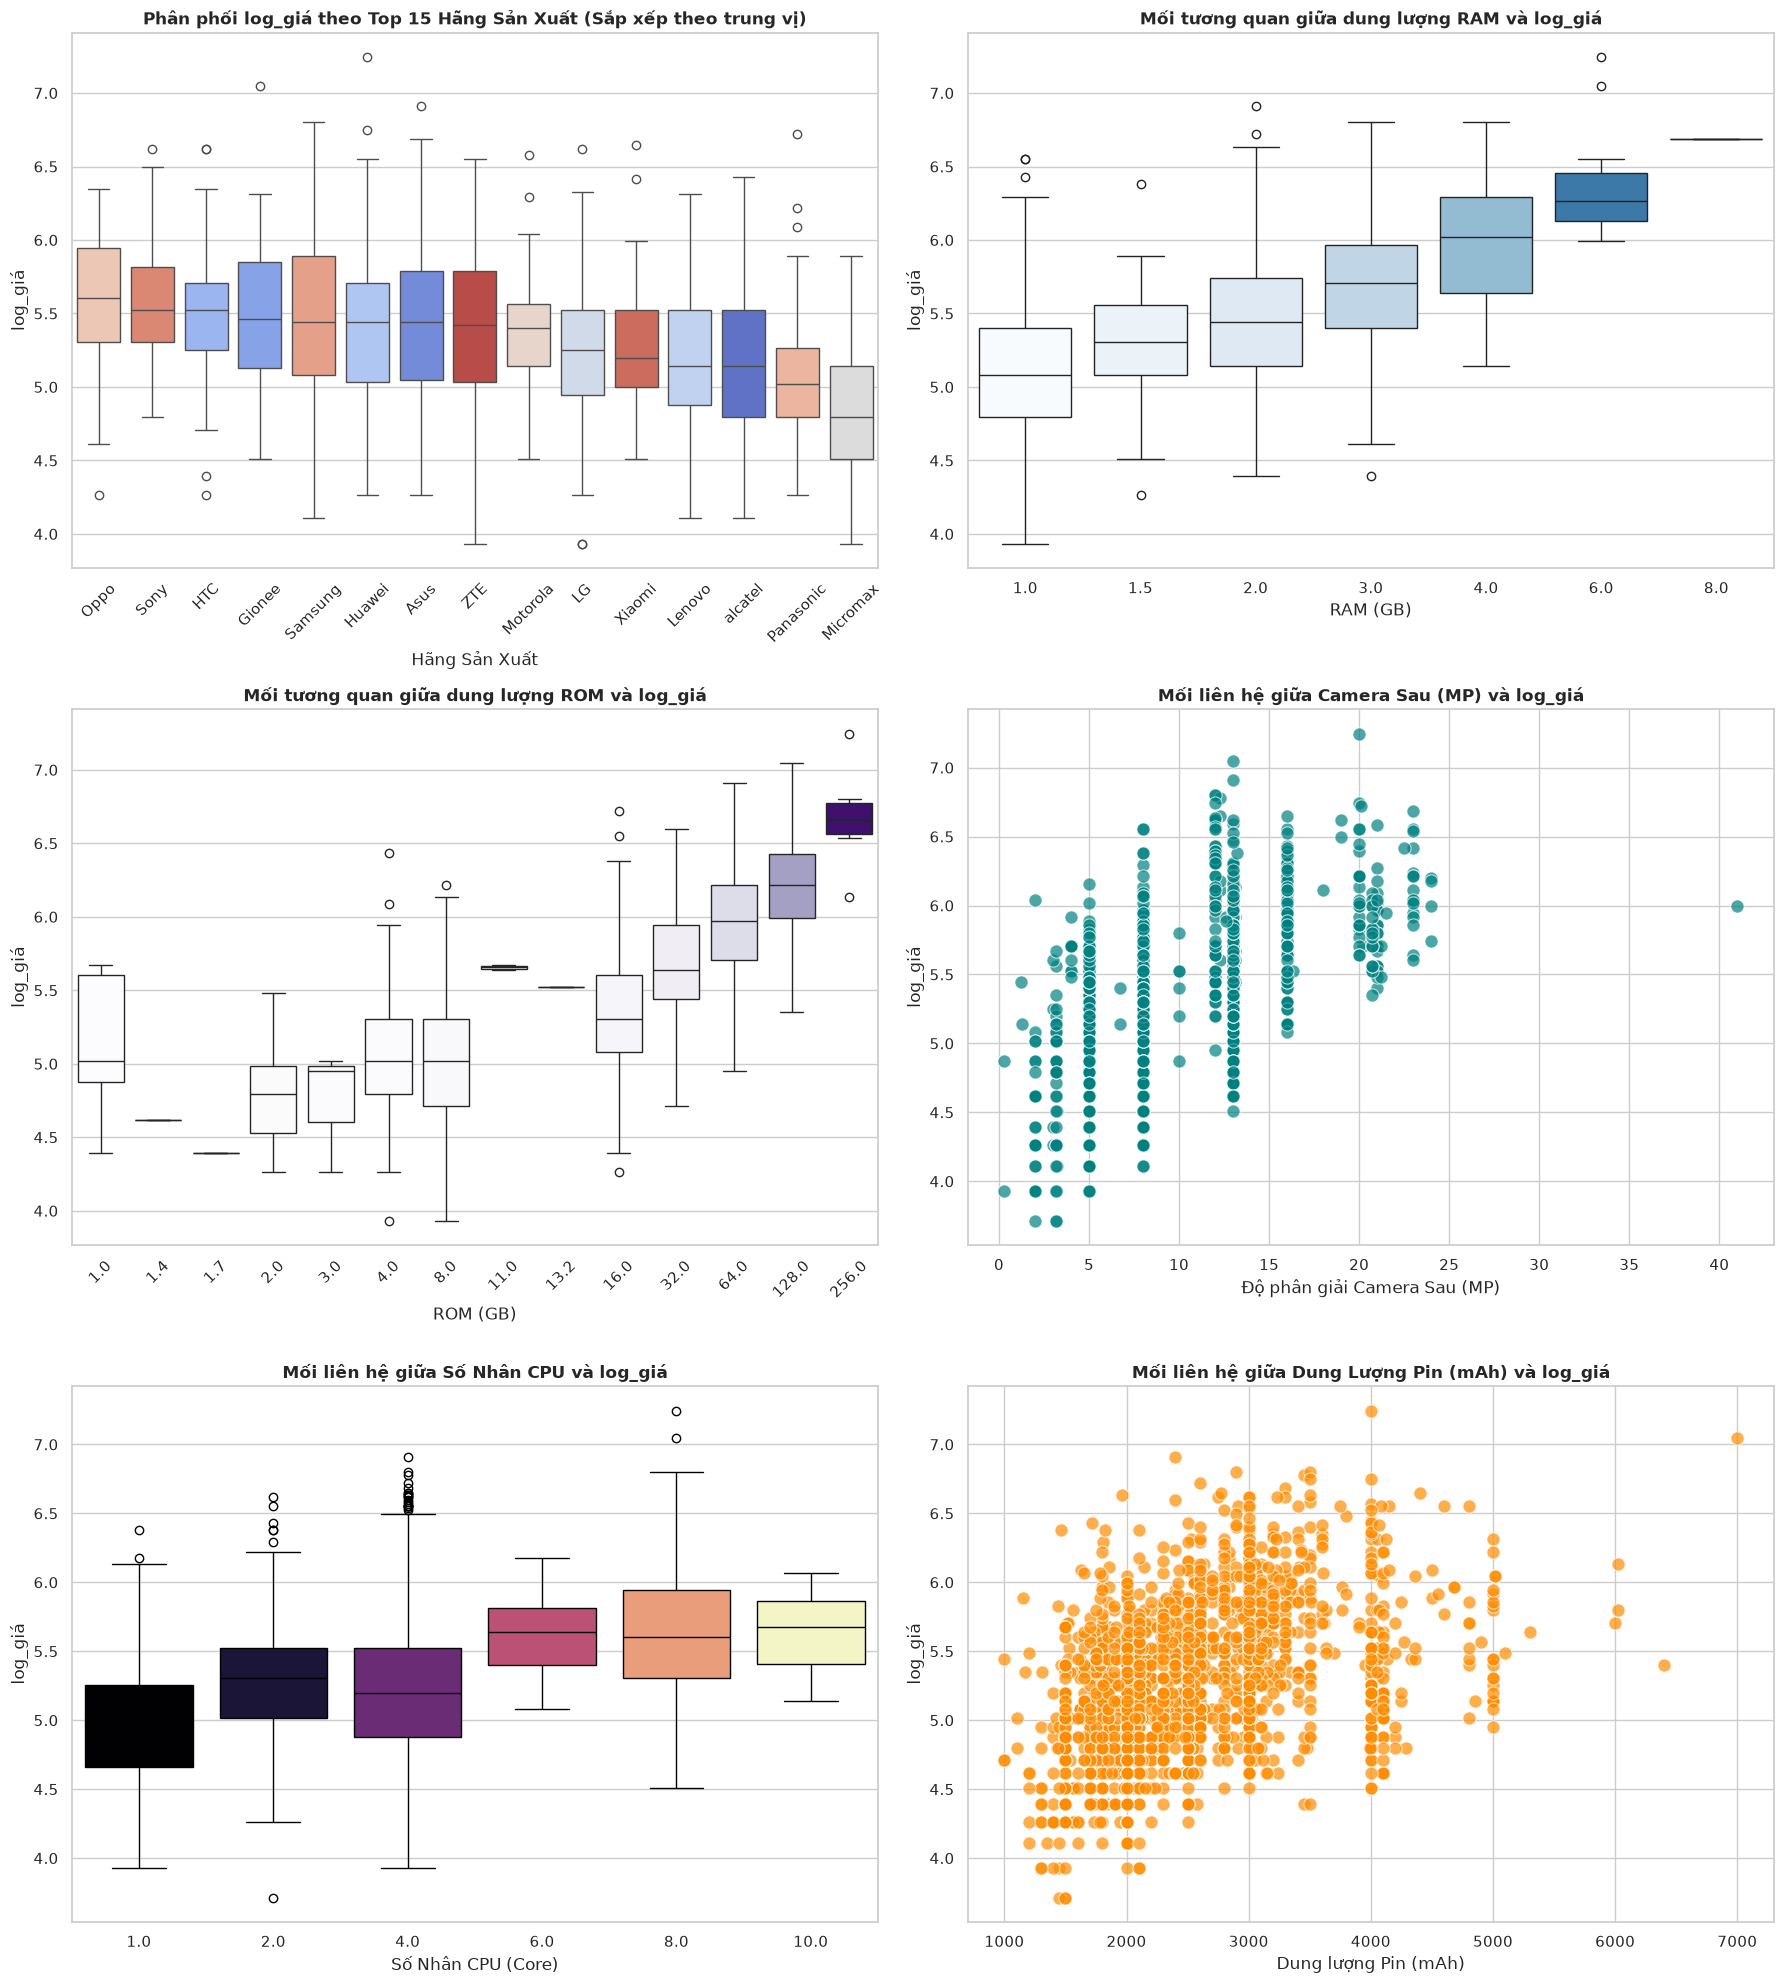

In [7]:
# Tạo bản sao df_eda để quan sát trực quan mà không ảnh hưởng đến tập dữ liệu chính
df_eda = df.copy()
df_eda['log_giá'] = np.log1p(df_eda['Giá Bán (EUR)'])

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(18, 20))
axes = axes.flatten()

# 1. log_giá theo Hãng Sản Xuất (Lấy Top 15 hãng có nhiều mẫu máy nhất, sắp xếp theo trung vị)
top_brands = df_eda['Hãng Sản Xuất'].value_counts().head(15).index
df_top_brands = df_eda[df_eda['Hãng Sản Xuất'].isin(top_brands)]
brand_order = df_top_brands.groupby('Hãng Sản Xuất')['log_giá'].median().sort_values(ascending=False).index

sns.boxplot(data=df_top_brands, x='Hãng Sản Xuất', y='log_giá', ax=axes[0], palette='coolwarm', order=brand_order, hue='Hãng Sản Xuất', legend=False)
axes[0].set_title('Phân phối log_giá theo Top 15 Hãng Sản Xuất (Sắp xếp theo trung vị)', fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_xlabel('Hãng Sản Xuất')
axes[0].set_ylabel('log_giá')

# 2. log_giá theo lượng RAM (GB)
sns.boxplot(data=df_eda, x='RAM (GB)', y='log_giá', ax=axes[1], palette='Blues', hue='RAM (GB)', legend=False)
axes[1].set_title('Mối tương quan giữa dung lượng RAM và log_giá', fontsize=12, fontweight='bold')
axes[1].set_xlabel('RAM (GB)')
axes[1].set_ylabel('log_giá')

# 3. log_giá theo lượng ROM (GB)
sns.boxplot(data=df_eda, x='ROM (GB)', y='log_giá', ax=axes[2], palette='Purples', hue='ROM (GB)', legend=False)
axes[2].set_title('Mối tương quan giữa dung lượng ROM và log_giá', fontsize=12, fontweight='bold')
axes[2].tick_params(axis='x', rotation=45)
axes[2].set_xlabel('ROM (GB)')
axes[2].set_ylabel('log_giá')

# 4. log_giá theo Độ phân giải Camera Sau (MP)
sns.scatterplot(data=df_eda, x='Camera Sau (MP)', y='log_giá', ax=axes[3], alpha=0.7, color='teal', s=90)
axes[3].set_title('Mối liên hệ giữa Camera Sau (MP) và log_giá', fontsize=12, fontweight='bold')
axes[3].set_xlabel('Độ phân giải Camera Sau (MP)')
axes[3].set_ylabel('log_giá')

# 5. log_giá theo Số Nhân CPU (Core)
sns.boxplot(data=df_eda, x='Số Nhân CPU (Core)', y='log_giá', ax=axes[4], palette='magma', hue='Số Nhân CPU (Core)', legend=False)
axes[4].set_title('Mối liên hệ giữa Số Nhân CPU và log_giá', fontsize=12, fontweight='bold')
axes[4].set_xlabel('Số Nhân CPU (Core)')
axes[4].set_ylabel('log_giá')

# 6. log_giá theo Dung Lượng Pin (mAh)
sns.scatterplot(data=df_eda, x='Dung Lượng Pin (mAh)', y='log_giá', ax=axes[5], alpha=0.7, color='darkorange', s=90)
axes[5].set_title('Mối liên hệ giữa Dung Lượng Pin (mAh) và log_giá', fontsize=12, fontweight='bold')
axes[5].set_xlabel('Dung lượng Pin (mAh)')
axes[5].set_ylabel('log_giá')

plt.tight_layout()
plt.show()

**Thương hiệu, RAM, ROM, Số nhân CPU và Camera sau:**  
Ta thấy chúng có một mối quan hệ đồng biến khá rõ ràng với `log_giá`. Các hãng định vị phân khúc cao như Apple, Sony, BlackBerry hay Samsung có mức giá trung vị nhỉnh hơn hẳn các hãng giá rẻ như Micromax, Spice, Celkon.  
Ở các mức dung lượng chuẩn từ 4GB -> 8GB -> 16GB -> 32GB -> 64GB -> 128GB -> 256GB, giá bán tăng rất đều theo dung lượng bộ nhớ.

### 5. Thử nghiệm và Khám phá các đặc trưng phái sinh (Feature Ideas)

**Về dung lượng pin và độ dày thân máy:**  
Khi quan sát riêng lẻ dung lượng pin, các dòng máy giá rẻ nhưng thiết kế dày cộp, pin lớn làm phân tán xu hướng. Do đó em thử nghiệm lấy **Dung lượng pin / Độ dày** (đặc trưng này phản ánh mức độ tối ưu không gian linh kiện bên trong thân máy: pin lớn nhưng máy vẫn mỏng gọn) và thu được xu hướng đồng biến rõ ràng hơn với `log_giá`. Đồng thời phát hiện một điểm ngoại lai cực đoan (`Tỷ số Pin/Độ Dày >= 800`).

Số lượng điểm ngoại lai Tỷ số Pin/Độ Dày >= 800: 1 dòng.


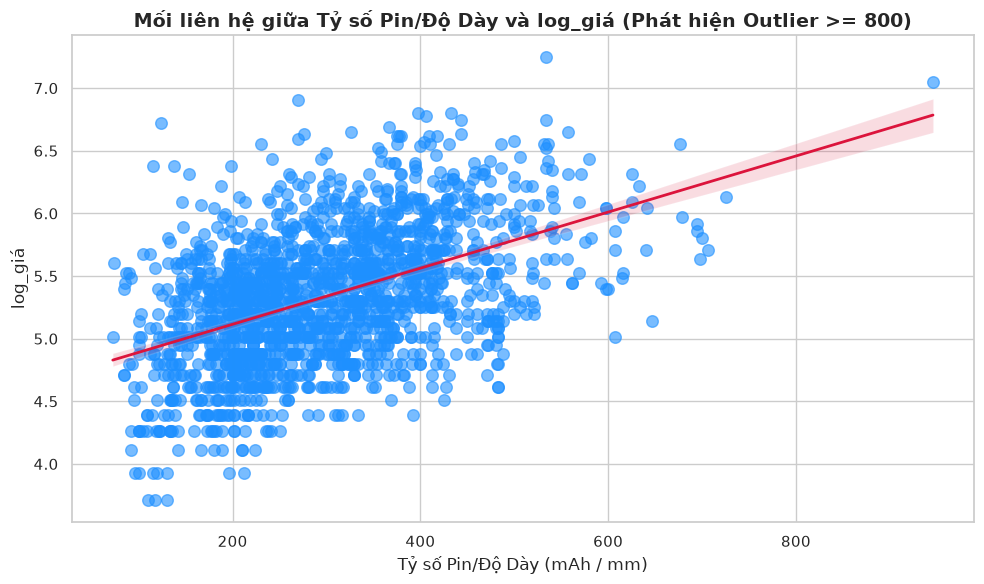

,Hãng Sản Xuất,Giá Bán (EUR),Dung Lượng Pin (mAh),Độ Dày (mm),Tỷ số Pin/Độ Dày
371,Gionee,1150.0,7000.0,7.4,945.945946


In [8]:
# Tính toán thử nghiệm Tỷ số Pin/Độ Dày
df_eda['Tỷ số Pin/Độ Dày'] = df_eda['Dung Lượng Pin (mAh)'] / df_eda['Độ Dày (mm)']

plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_eda,
    x='Tỷ số Pin/Độ Dày',
    y='log_giá',
    scatter_kws={'alpha': 0.6, 'color': 'dodgerblue', 's': 70},
    line_kws={'color': 'crimson', 'linewidth': 2}
)
plt.title('Mối liên hệ giữa Tỷ số Pin/Độ Dày và log_giá (Phát hiện Outlier >= 800)', fontsize=14, fontweight='bold')
plt.xlabel('Tỷ số Pin/Độ Dày (mAh / mm)', fontsize=12)
plt.ylabel('log_giá', fontsize=12)
plt.tight_layout()
plt.show()

# Kiểm tra điểm outlier Tỷ số Pin/Độ Dày >= 800
pin_thick_outliers = df_eda[df_eda['Tỷ số Pin/Độ Dày'] >= 800]
print(f"Số lượng điểm ngoại lai Tỷ số Pin/Độ Dày >= 800: {len(pin_thick_outliers)} dòng.")
if len(pin_thick_outliers) > 0:
    display(pin_thick_outliers[['Hãng Sản Xuất', 'Giá Bán (EUR)', 'Dung Lượng Pin (mAh)', 'Độ Dày (mm)', 'Tỷ số Pin/Độ Dày']])

**Về công nghệ tấm nền màn hình:**  
Hiện tại đang có nhiều phân loại tấm nền chi tiết, tuy nhiên ta có thể chia thành 2 nhóm chính là phân khúc cao cấp: `OLED/AMOLED`; và phân khúc phổ thông dùng `LCD` (IPS, TFT, PLS, Super LCD). Ta sẽ phân nhóm và kiểm tra sự phân bố theo giá.

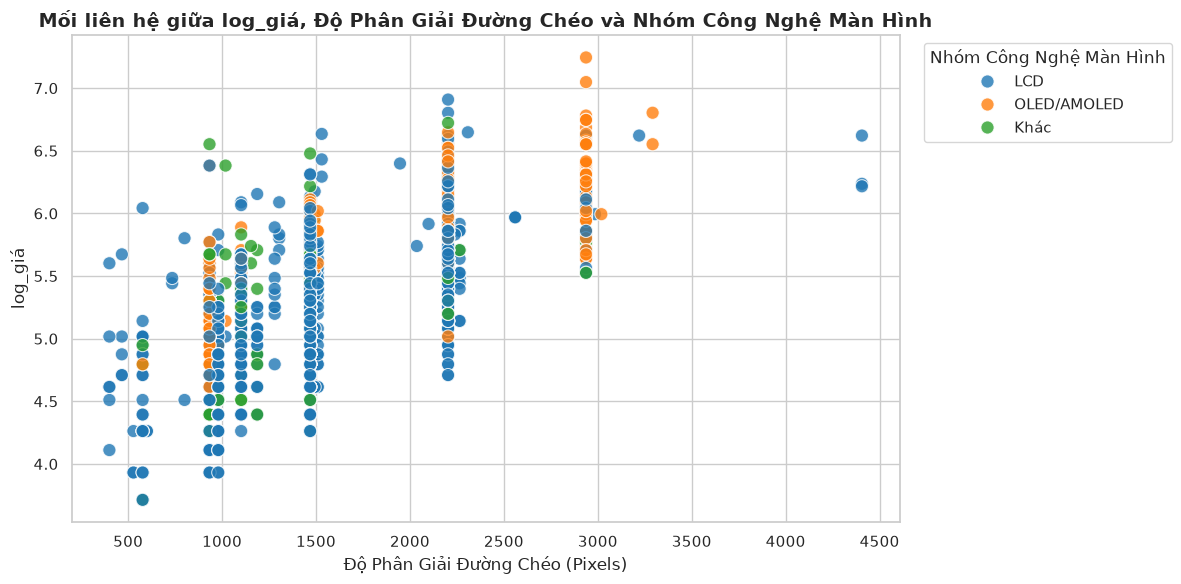

In [9]:
def phan_nhom_man_hinh_eda(tam_nen):
    if pd.isna(tam_nen):
        return 'Khác'
    tam_nen_lower = str(tam_nen).lower()
    if 'oled' in tam_nen_lower or 'amoled' in tam_nen_lower:
        return 'OLED/AMOLED'
    elif any(x in tam_nen_lower for x in ['lcd', 'tft', 'pls', 'ips']):
        return 'LCD'
    else:
        return 'Khác'

df_eda['Nhóm Công Nghệ Màn Hình'] = df_eda['Tấm Nền Màn Hình'].apply(phan_nhom_man_hinh_eda)

plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_eda,
    x='Độ Phân Giải Đường Chéo (Pixels)',
    y='log_giá',
    hue='Nhóm Công Nghệ Màn Hình',
    palette='tab10',
    alpha=0.8,
    s=90
)
plt.title('Mối liên hệ giữa log_giá, Độ Phân Giải Đường Chéo và Nhóm Công Nghệ Màn Hình', fontsize=14, fontweight='bold')
plt.xlabel('Độ Phân Giải Đường Chéo (Pixels)', fontsize=12)
plt.ylabel('log_giá', fontsize=12)
plt.legend(title='Nhóm Công Nghệ Màn Hình', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Về công nghệ tấm nền:**  
Ta có thể thấy sự phân nhóm tương đối rõ về tầm giá và độ phân giải. Từ đây ta có thể tự tin tiếp tục phân chia theo nhóm này và giữ thành các features để phục vụ mô hình sau này.

**Về mật độ Pixels (PPI) và Tổng Xung Nhịp CPU:**  
Thay vì chỉ xét kích thước màn hình đơn thuần, em kết hợp độ phân giải đường chéo và kích thước màn hình để tạo thành mật độ điểm ảnh **PPI**, đồng thời kết hợp số nhân và tốc độ xung nhịp thành **Tổng Xung Nhịp CPU** để đo lường sức mạnh xử lý tổng hợp:

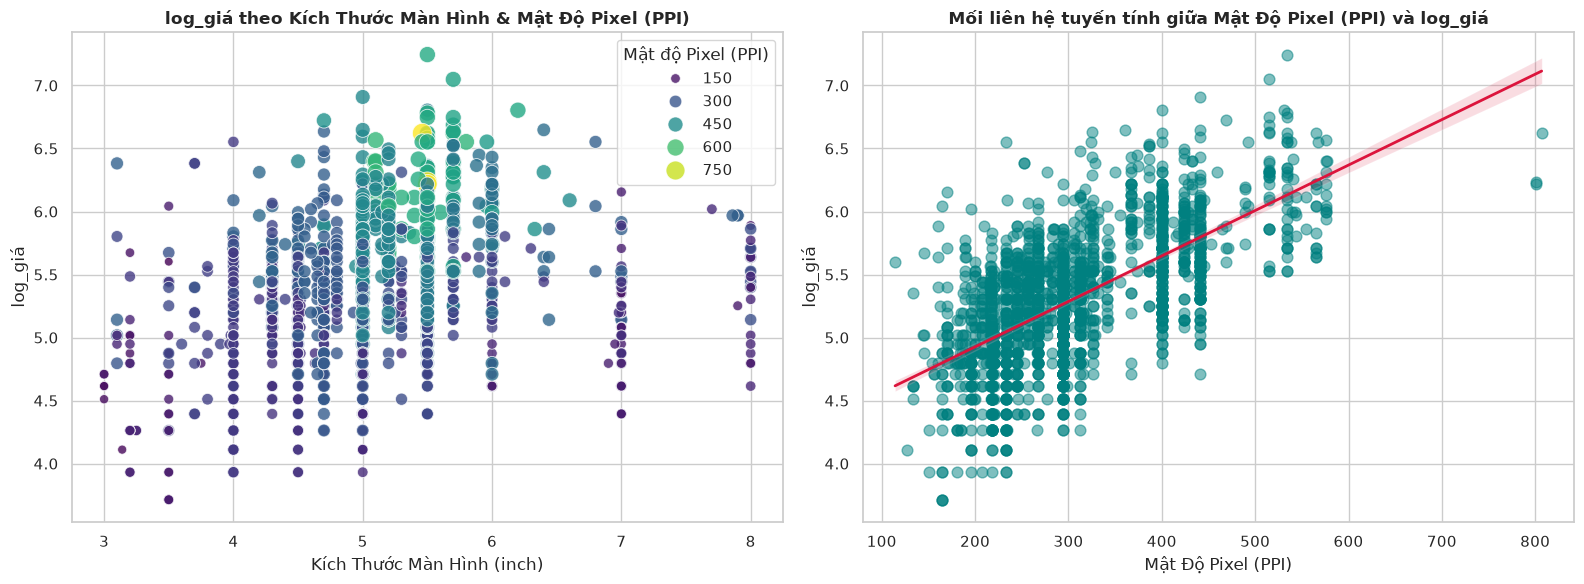

In [10]:
# Tính toán PPI chuẩn và Tổng Xung Nhịp CPU
df_eda['Mật độ Pixel (PPI)'] = df_eda['Độ Phân Giải Đường Chéo (Pixels)'] / df_eda['Kích Thước Màn Hình (inch)']
df_eda['Tổng Xung Nhịp CPU'] = df_eda['Số Nhân CPU (Core)'] * df_eda['Xung Nhịp CPU (GHz)']

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# 1. Kích thước màn hình vs log_giá (Phân loại theo Mật độ pixel)
sns.scatterplot(
    data=df_eda,
    x='Kích Thước Màn Hình (inch)',
    y='log_giá',
    hue='Mật độ Pixel (PPI)',
    palette='viridis',
    size='Mật độ Pixel (PPI)',
    sizes=(40, 200),
    alpha=0.8,
    ax=axes[0]
)
axes[0].set_title('log_giá theo Kích Thước Màn Hình & Mật Độ Pixel (PPI)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kích Thước Màn Hình (inch)')
axes[0].set_ylabel('log_giá')

# 2. Mật độ Pixel trực tiếp vs log_giá
sns.regplot(
    data=df_eda,
    x='Mật độ Pixel (PPI)',
    y='log_giá',
    scatter_kws={'alpha': 0.5, 'color': 'teal', 's': 60},
    line_kws={'color': 'crimson', 'linewidth': 2},
    ax=axes[1]
)
axes[1].set_title('Mối liên hệ tuyến tính giữa Mật Độ Pixel (PPI) và log_giá', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Mật Độ Pixel (PPI)')
axes[1].set_ylabel('log_giá')

plt.tight_layout()
plt.show()

### 6. Phân tích Phân phối Giá theo Cảm Biến Vân Tay, Hỗ Trợ Mạng, Thiết Kế Pin, NFC, Năm Ra Mắt và Hãng Chip

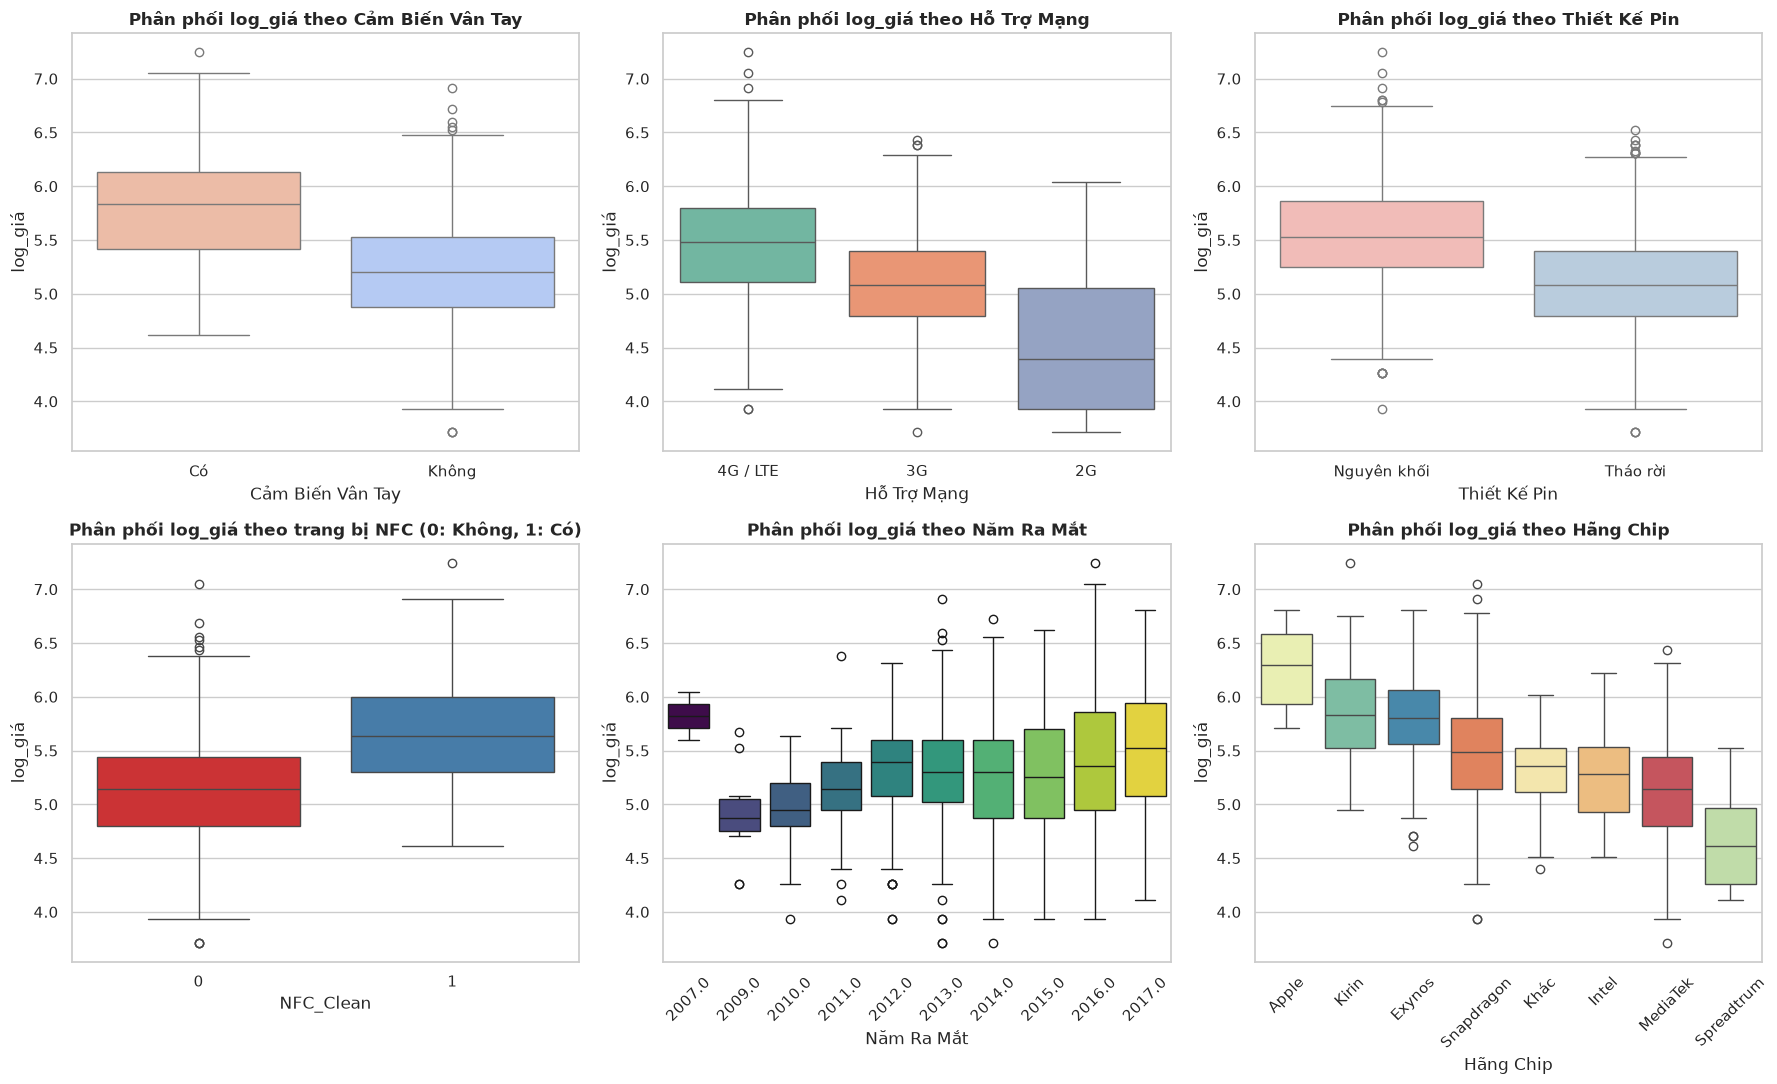

In [11]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11))
axes = axes.flatten()

# 1. Phân phối giá theo Cảm Biến Vân Tay
fp_order = df_eda.groupby('Cảm Biến Vân Tay')['log_giá'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_eda,
    x='Cảm Biến Vân Tay',
    y='log_giá',
    ax=axes[0],
    palette='coolwarm',
    order=fp_order,
    hue='Cảm Biến Vân Tay',
    legend=False
)
axes[0].set_title('Phân phối log_giá theo Cảm Biến Vân Tay', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Cảm Biến Vân Tay')
axes[0].set_ylabel('log_giá')

# 2. Phân phối giá theo Hỗ Trợ Mạng
network_order = df_eda.groupby('Hỗ Trợ Mạng')['log_giá'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_eda,
    x='Hỗ Trợ Mạng',
    y='log_giá',
    ax=axes[1],
    palette='Set2',
    order=network_order,
    hue='Hỗ Trợ Mạng',
    legend=False
)
axes[1].set_title('Phân phối log_giá theo Hỗ Trợ Mạng', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hỗ Trợ Mạng')
axes[1].set_ylabel('log_giá')

# 3. Phân phối giá theo Thiết Kế Pin
bat_order = df_eda.groupby('Thiết Kế Pin')['log_giá'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_eda,
    x='Thiết Kế Pin',
    y='log_giá',
    ax=axes[2],
    palette='Pastel1',
    order=bat_order,
    hue='Thiết Kế Pin',
    legend=False
)
axes[2].set_title('Phân phối log_giá theo Thiết Kế Pin', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Thiết Kế Pin')
axes[2].set_ylabel('log_giá')

# 4. Phân phối giá theo NFC_Clean
sns.boxplot(
    data=df_eda,
    x='NFC_Clean',
    y='log_giá',
    ax=axes[3],
    palette='Set1',
    hue='NFC_Clean',
    legend=False
)
axes[3].set_title('Phân phối log_giá theo trang bị NFC (0: Không, 1: Có)', fontsize=12, fontweight='bold')
axes[3].set_xlabel('NFC_Clean')
axes[3].set_ylabel('log_giá')

# 5. Phân phối giá theo Năm Ra Mắt
sns.boxplot(
    data=df_eda,
    x='Năm Ra Mắt',
    y='log_giá',
    ax=axes[4],
    palette='viridis',
    hue='Năm Ra Mắt',
    legend=False
)
axes[4].set_title('Phân phối log_giá theo Năm Ra Mắt', fontsize=12, fontweight='bold')
axes[4].tick_params(axis='x', rotation=45)
axes[4].set_xlabel('Năm Ra Mắt')
axes[4].set_ylabel('log_giá')

# 6. Phân phối giá theo Hãng Chip
chip_order = df_eda.groupby('Hãng Chip')['log_giá'].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_eda,
    x='Hãng Chip',
    y='log_giá',
    ax=axes[5],
    palette='Spectral',
    order=chip_order,
    hue='Hãng Chip',
    legend=False
)
axes[5].set_title('Phân phối log_giá theo Hãng Chip', fontsize=12, fontweight='bold')
axes[5].tick_params(axis='x', rotation=45)
axes[5].set_xlabel('Hãng Chip')
axes[5].set_ylabel('log_giá')

plt.tight_layout()
plt.show()

Ta thấy sự trang bị cảm biến vân tay, kết nối NFC, chuẩn mạng di động, thiết kế pin và dòng vi xử lý đều có sự phân hóa rất rõ theo giá tiền. Các mẫu máy tích hợp bảo mật vân tay, có NFC (`NFC_Clean = 1`), hỗ trợ 4G/LTE và thiết kế pin nguyên khối thường thuộc phân khúc tầm trung - cao cấp. Ngoài ra, kết hợp `Năm Ra Mắt` với cấu hình phần cứng sẽ giúp mô hình phân biệt tốt giữa máy flagship đời cũ và máy phổ thông đời mới có cùng dung lượng RAM/ROM.

### 7. Khảo sát RAM và Dung lượng Pin theo Phân khúc Giá để Định hình Chiến lược Imputation

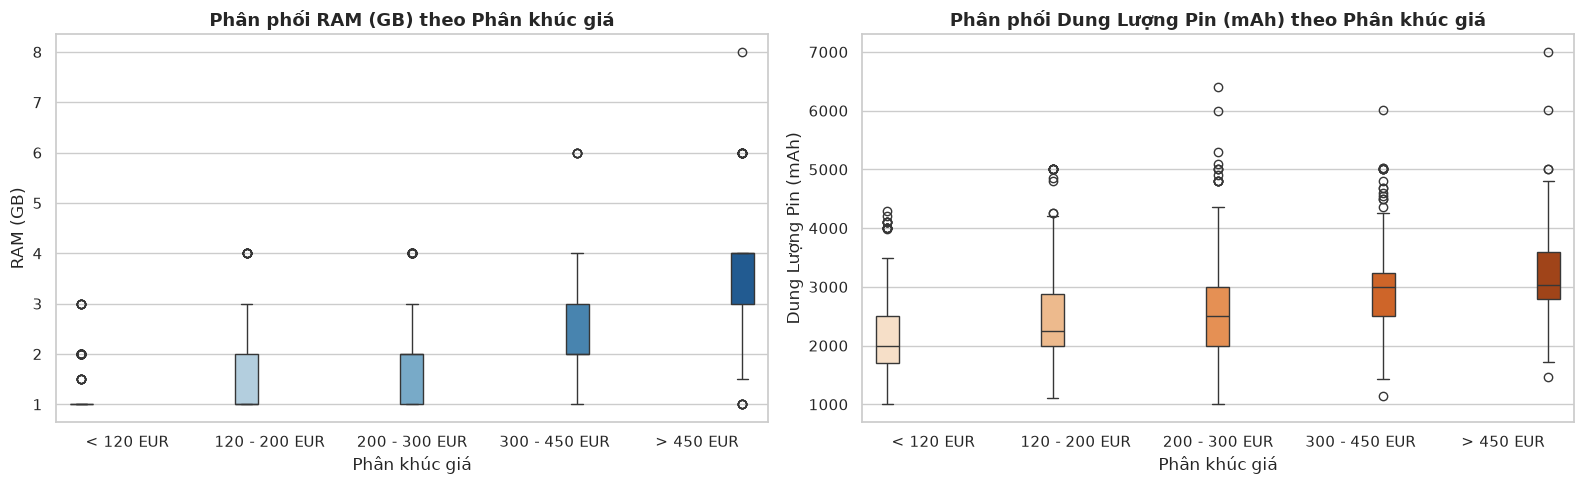

In [12]:
bins = [0, 120, 200, 300, 450, np.inf]
labels = ['< 120 EUR', '120 - 200 EUR', '200 - 300 EUR', '300 - 450 EUR', '> 450 EUR']
df_eda['Phân khúc giá'] = pd.cut(df_eda['Giá Bán (EUR)'], bins=bins, labels=labels)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

sns.boxplot(data=df_eda, x='Phân khúc giá', y='RAM (GB)', ax=axes[0], palette='Blues', hue='Phân khúc giá', legend=False)
axes[0].set_title('Phân phối RAM (GB) theo Phân khúc giá', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Phân khúc giá')
axes[0].set_ylabel('RAM (GB)')

sns.boxplot(data=df_eda, x='Phân khúc giá', y='Dung Lượng Pin (mAh)', ax=axes[1], palette='Oranges', hue='Phân khúc giá', legend=False)
axes[1].set_title('Phân phối Dung Lượng Pin (mAh) theo Phân khúc giá', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Phân khúc giá')
axes[1].set_ylabel('Dung Lượng Pin (mAh)')

plt.tight_layout()
plt.show()

### ĐÚC KẾT CHIẾN LƯỢC TIỀN XỬ LÝ

1. **Về RAM (GB), Kích thước màn hình, Tỷ lệ màn hình, Độ phân giải đường chéo, Dung lượng Pin, Độ dày, Trọng lượng và Xung nhịp CPU:**  
   Phân bố liên tục hoặc hội tụ quanh vùng trung tâm (riêng `RAM (GB)` có trung vị ở mức `1.5 GB`) $\rightarrow$ sẽ điền **Median của tập Train** để tránh ảnh hưởng của các giá trị ngoại lai.
2. **Về ROM, Camera Sau, Camera Trước, Số Nhân CPU và Năm Ra Mắt:**  
   Có các mốc thông số chuẩn rời rạc rõ rệt (như ROM 8/16 GB, Camera 5/8 MP, CPU 4 nhân, Năm ra mắt 2014) $\rightarrow$ sẽ điền **Mode của tập Train** (cột `NFC_Clean` đã đầy đủ 100% dưới dạng nhị phân `0/1`).
3. **Về Tấm nền màn hình và Hãng Chip:**  
   Là các biến phân loại nên sẽ điền **Mode** dựa trên tần suất xuất hiện nhiều nhất trên tập Train.

## PHẦN II: PHÂN CHIA TẬP DỮ LIỆU (TRAIN / VALIDATION / TEST SPLIT)
Để đảm bảo mô hình được đánh giá hoàn toàn khách quan và ngăn chặn triệt để hiện tượng rò rỉ dữ liệu (Data Leakage), chúng ta thực hiện phân chia tập dữ liệu ngay tại đây:
- **Train Set (70%)**: Dùng để học các giá trị thống kê, trích xuất đặc trưng và huấn luyện mô hình.
- **Validation Set (15%)**: Dùng để tinh chỉnh siêu tham số và đánh giá quá trình thử nghiệm.
- **Test Set (15%)**: Dùng để đánh giá hiệu năng cuối cùng trên dữ liệu thực tế chưa từng thấy.

*(Cột 'Phân khúc giá' chỉ được tạo tạm thời để làm nhãn phân tầng Stratify, giúp tỷ lệ các mức giá được phân bố đồng đều giữa 3 tập).*

In [13]:
# 1. Tạo nhãn phân khúc giá chỉ phục vụ Stratified Split
bins = [0, 120, 200, 300, 450, np.inf]
labels = ['< 120 EUR', '120 - 200 EUR', '200 - 300 EUR', '300 - 450 EUR', '> 450 EUR']
stratify_labels = pd.cut(df['Giá Bán (EUR)'], bins=bins, labels=labels)

# 2. Chia thành tập Train (70%) và Temp (30%)
df_train, df_temp = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=stratify_labels
)

# 3. Chia tập Temp thành Validation (15%) và Test (15%)
stratify_temp = stratify_labels.loc[df_temp.index]
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=42,
    stratify=stratify_temp
)

# Tạo bản sao độc lập và reset index
df_train = df_train.copy().reset_index(drop=True)
df_val = df_val.copy().reset_index(drop=True)
df_test = df_test.copy().reset_index(drop=True)

print(f"Kích thước tập huấn luyện (Train Set):       {df_train.shape[0]} dòng (70%)")
print(f"Kích thước tập kiểm thử quá trình (Val Set):  {df_val.shape[0]} dòng (15%)")
print(f"Kích thước tập đánh giá cuối cùng (Test Set): {df_test.shape[0]} dòng (15%)")

Kích thước tập huấn luyện (Train Set):       1337 dòng (70%)
Kích thước tập kiểm thử quá trình (Val Set):  286 dòng (15%)
Kích thước tập đánh giá cuối cùng (Test Set): 287 dòng (15%)


## PHẦN III: TIỀN XỬ LÝ TỐI THIỂU CHO BASELINE MODEL

Theo đúng quy trình xây dựng mô hình chuẩn:
- Sau khi chia tập dữ liệu, chúng ta **chưa vội đưa các đặc trưng phái sinh phức tạp** (như Tỷ số Pin/Độ Dày, Mật độ PPI, Tổng xung nhịp CPU, phân nhóm tấm nền...) vào bảng dữ liệu chính thức.
- Ở bước này, chúng ta **chỉ thực hiện tiền xử lý tối thiểu (Minimal Preprocessing)** vừa đủ để mô hình Machine Learning có thể nhận diện và xử lý dữ liệu:
  1. **Điền giá trị thiếu (Missing Values):** Điền trực tiếp bằng **Median / Mode** học từ tập Train cho từng nhóm thuộc tính.
  2. **Mã hóa biến phân loại (Encoding):** Sử dụng One-Hot Encoding cơ bản cho các cột phân loại nguyên bản (`Hãng Sản Xuất`, `Tấm Nền Màn Hình`, `Thiết Kế Pin`, `Hỗ Trợ Mạng`, `Cảm Biến Vân Tay`, `Hãng Chip`).
  3. **Biến mục tiêu ($y$):** Giữ nguyên `Giá Bán (EUR)` gốc để đo đạc sai số thực tế theo đơn vị EUR.

Mục tiêu cốt lõi: **Xây dựng ngay mô hình Baseline làm mốc chuẩn (Benchmark)** để có căn cứ định lượng đánh giá cho các vòng cải tiến tiếp theo!

In [14]:
# 1. Khai báo danh sách các cột phân loại và số học nguyên bản
numeric_cols = [
    'RAM (GB)', 'ROM (GB)', 'Kích Thước Màn Hình (inch)',
    'Tỷ Lệ Màn Hình (%)', 'Camera Sau (MP)', 'Camera Trước (MP)',
    'Dung Lượng Pin (mAh)', 'Độ Dày (mm)', 'Trọng Lượng (g)',
    'Số Nhân CPU (Core)', 'Xung Nhịp CPU (GHz)',
    'Năm Ra Mắt', 'NFC_Clean', 'Độ Phân Giải Đường Chéo (Pixels)'
]

discrete_mode_cols = [
    'ROM (GB)', 'Camera Sau (MP)', 'Camera Trước (MP)',
    'Số Nhân CPU (Core)', 'Năm Ra Mắt', 'NFC_Clean'
]

cat_cols = [
    'Hãng Sản Xuất', 'Tấm Nền Màn Hình', 'Thiết Kế Pin',
    'Hỗ Trợ Mạng', 'Cảm Biến Vân Tay', 'Hãng Chip'
]

# 2. Học các giá trị thống kê CHỈ TỪ tập df_train
train_stats = {}
for col in numeric_cols:
    if col in discrete_mode_cols:
        train_stats[col] = df_train[col].mode()[0]
    else:
        train_stats[col] = df_train[col].median()

for col in cat_cols:
    train_stats[col] = df_train[col].mode()[0]

print("--- THỐNG KÊ TỐI THIỂU HỌC TỪ TẬP TRAIN ---")
for k, v in list(train_stats.items())[:10]:
    print(f" - {k}: {v}")

# 3. Hàm tiền xử lý tối thiểu (Fit on Train -> Transform on Val/Test)
def minimal_preprocess(df_input, stats, train_dummy_cols=None):
    data = df_input.copy()
    
    # Điền missing cho cột số bằng Median/Mode của tập Train
    for col in numeric_cols:
        data[col] = data[col].fillna(stats[col])
        
    # Điền missing cho cột phân loại bằng Mode của tập Train
    for col in cat_cols:
        data[col] = data[col].fillna(stats[col])
        
    # One-Hot Encoding cơ bản cho các cột phân loại gốc
    data_encoded = pd.get_dummies(data, columns=cat_cols, drop_first=True)
    
    # Khớp đồng nhất danh sách cột với tập Train
    if train_dummy_cols is not None:
        data_encoded = data_encoded.reindex(columns=train_dummy_cols, fill_value=0)
        
    return data_encoded

# Áp dụng cho tập Train trước để lấy chuẩn cột
df_train_proc = minimal_preprocess(df_train, train_stats)
train_encoded_cols = df_train_proc.columns.tolist()

# Áp dụng cho tập Val và Test
df_val_proc = minimal_preprocess(df_val, train_stats, train_dummy_cols=train_encoded_cols)
df_test_proc = minimal_preprocess(df_test, train_stats, train_dummy_cols=train_encoded_cols)

print(f"\nĐã tiền xử lý tối thiểu thành công:")
print(f"Train: {df_train_proc.shape}, Missing còn lại: {df_train_proc.isnull().sum().sum()}")
print(f"Val:   {df_val_proc.shape}, Missing còn lại: {df_val_proc.isnull().sum().sum()}")
print(f"Test:  {df_test_proc.shape}, Missing còn lại: {df_test_proc.isnull().sum().sum()}")

--- THỐNG KÊ TỐI THIỂU HỌC TỪ TẬP TRAIN ---
 - RAM (GB): 1.75
 - ROM (GB): 16.0
 - Kích Thước Màn Hình (inch): 5.0
 - Tỷ Lệ Màn Hình (%): 67.5
 - Camera Sau (MP): 8.0
 - Camera Trước (MP): 5.0
 - Dung Lượng Pin (mAh): 2470.0
 - Độ Dày (mm): 8.9
 - Trọng Lượng (g): 149.0
 - Số Nhân CPU (Core): 4.0

Đã tiền xử lý tối thiểu thành công:
Train: (1337, 91), Missing còn lại: 0
Val:   (286, 91), Missing còn lại: 0
Test:  (287, 91), Missing còn lại: 0


### Tách Biến Đặc Trưng (X) và Biến Mục Tiêu (y)
Biến mục tiêu $y$ là `Giá Bán (EUR)` gốc để dễ dàng đánh giá sai số tuyệt đối (MAE) tính theo đơn vị tiền tệ thực tế.

In [15]:
target_col = 'Giá Bán (EUR)'

X_train = df_train_proc.drop(columns=[target_col])
y_train = df_train_proc[target_col]

X_val = df_val_proc.drop(columns=[target_col])
y_val = df_val_proc[target_col]

X_test = df_test_proc.drop(columns=[target_col])
y_test = df_test_proc[target_col]

print("Cấu trúc dữ liệu sẵn sàng cho Baseline Model:")
print(f" - X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f" - X_val:   {X_val.shape}, y_val:   {y_val.shape}")
print(f" - X_test:  {X_test.shape}, y_test:  {y_test.shape}")

Cấu trúc dữ liệu sẵn sàng cho Baseline Model:
 - X_train: (1337, 90), y_train: (1337,)
 - X_val:   (286, 90), y_val:   (286,)
 - X_test:  (287, 90), y_test:  (287,)


## PHẦN IV: XÂY DỰNG VÀ ĐÁNH GIÁ BASELINE MODEL (Bước 6)

Chúng ta tiến hành huấn luyện 3 mô hình cơ sở:
1. **Linear Regression**: Mô hình tuyến tính cơ bản để kiểm tra mối quan hệ tuyến tính giữa các thuộc tính và giá bán.
2. **Random Forest Regressor (Mặc định)**: Mô hình cây quyết định đa biến, không cần scaling, có khả năng tự động học các tương tác phi tuyến tính phức tạp giữa các đặc trưng.
3. **XGBoost Regressor (Mặc định)**: Mô hình Gradient Boosting mạnh mẽ trên dữ liệu dạng bảng.

Chúng ta đánh giá trên tập **Validation** qua 3 chỉ số:
- **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình (đơn vị: EUR).
- **RMSE (Root Mean Squared Error):** Căn bậc hai sai số bình phương trung bình (phạt nặng các sai số lớn).
- **R² Score:** Mức độ giải thích phương sai của mô hình (càng gần 1 càng tốt).

In [16]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from xgboost import XGBRegressor

# Khởi tạo các mô hình cơ sở
baseline_models = {
    'Linear Regression': LinearRegression(),
    'Random Forest (Default)': RandomForestRegressor(random_state=42),
    'XGBoost (Default)': XGBRegressor(random_state=42),
}

baseline_results = []

# Huấn luyện và Đánh giá trên tập Validation
for name, model in baseline_models.items():
    # Fit trên Train
    model.fit(X_train, y_train)

    # Dự đoán trên Validation
    y_pred_val = model.predict(X_val)

    # Tính các chỉ số đánh giá
    mae = mean_absolute_error(y_val, y_pred_val)
    rmse = root_mean_squared_error(y_val, y_pred_val)
    r2 = r2_score(y_val, y_pred_val)

    baseline_results.append({
        'Mô hình': name,
        'Val MAE (EUR)': f'{mae:,.2f} €',
        'Val RMSE (EUR)': f'{rmse:,.2f} €',
        'Val R² Score': round(r2, 4),
    })

# Hiển thị bảng tổng kết kết quả Baseline
df_baseline_results = pd.DataFrame(baseline_results)
print('=== BẢNG KẾT QUẢ BASELINE MODEL (MỐC THAM CHIẾU) ===')
display(df_baseline_results)

=== BẢNG KẾT QUẢ BASELINE MODEL (MỐC THAM CHIẾU) ===


,Mô hình,Val MAE (EUR),Val RMSE (EUR),Val R² Score
0,Linear Regression,58.20 €,86.23 €,0.6154
1,Random Forest (Default),52.32 €,75.88 €,0.7022
2,XGBoost (Default),51.46 €,77.98 €,0.6855


### Phân tích Kết quả Baseline và Định hướng Cải tiến Tiếp theo

> **Nhận xét kết quả Baseline:**
> - **Random Forest (Default)** đạt hiệu năng tổng thể tốt nhất trên cả 3 chỉ số với **MAE $\approx$ 52.32 €**, **RMSE $\approx$ 75.88 €** và hệ số xác định **$R^2 \approx$ 0.7022**, cho thấy khả năng nắm bắt tốt mối quan hệ phi tuyến giữa cấu hình, năm ra mắt, NFC và giá bán ngay cả khi chưa tinh chỉnh siêu tham số.
> - **XGBoost (Default)** đứng thứ hai với **MAE $\approx$ 51.46 €**, **RMSE $\approx$ 77.98 €** và **$R^2 \approx$ 0.6855**. Các mô hình Boosting mặc định thường nhạy cảm với siêu tham số và dữ liệu chưa qua xử lý chuyên sâu, dẫn đến hiện tượng overfit nhẹ trên tập huấn luyện.
> - **Linear Regression** có kết quả thấp nhất (**MAE $\approx$ 58.20 €**, **RMSE $\approx$ 86.23 €**, **$R^2 \approx$ 0.6154**), phản ánh việc định giá smartphone phụ thuộc nhiều vào sự kết hợp phi tuyến giữa các linh kiện theo từng thời kỳ ra mắt.

---

### 📌 Định hướng Cải tiến Tiếp theo

1. **Tối ưu hóa Siêu tham số (Hyperparameter Tuning):**
   - Tinh chỉnh **XGBoost** bằng `RandomizedSearchCV` hoặc `Optuna` (giảm `max_depth`, tinh chỉnh `learning_rate`, `subsample`, `colsample_bytree`) để kiểm soát overfitting và cải thiện $R^2$.
   - Tinh chỉnh thêm `n_estimators`, `max_depth`, `min_samples_split` cho **Random Forest** để kéo giảm RMSE hơn nữa.

2. **Xử lý Dữ liệu Ngoại lệ (Outliers) & Biến đổi Mục tiêu:**
   - Sự chênh lệch giữa MAE và RMSE ở cả 3 mô hình cho thấy tập dữ liệu có những mẫu máy cao cấp gây sai số lớn. Có thể kết hợp biến đổi `log_giá` và lọc bớt các điểm ngoại lai cực đoan trên tập Train.

3. **Kỹ thuật Đặc trưng (Feature Engineering):**
   - Đưa vào các biến tương tác đã khám phá ở phần EDA như `Mật độ Pixel (PPI)`, `Tỷ số Pin/Độ Dày`, `Tổng Xung Nhịp CPU` và gom nhóm `Nhóm Công Nghệ Màn Hình` để tăng khả năng học của các mô hình ở các notebook thử nghiệm tiếp theo.

In [17]:
pd.set_option('display.max_columns', None)
display(X_train.head())

,RAM (GB),ROM (GB),Kích Thước Màn Hình (inch),Tỷ Lệ Màn Hình (%),Camera Sau (MP),Camera Trước (MP),Dung Lượng Pin (mAh),Độ Dày (mm),Trọng Lượng (g),Số Nhân CPU (Core),Xung Nhịp CPU (GHz),Năm Ra Mắt,NFC_Clean,Độ Phân Giải Đường Chéo (Pixels),Hãng Sản Xuất_Allview,Hãng Sản Xuất_Amazon,Hãng Sản Xuất_Apple,Hãng Sản Xuất_Archos,Hãng Sản Xuất_Asus,Hãng Sản Xuất_BLU,Hãng Sản Xuất_BQ,Hãng Sản Xuất_BenQ,Hãng Sản Xuất_BlackBerry,Hãng Sản Xuất_Casio,Hãng Sản Xuất_Cat,Hãng Sản Xuất_Celkon,Hãng Sản Xuất_Coolpad,Hãng Sản Xuất_Dell,Hãng Sản Xuất_Gigabyte,Hãng Sản Xuất_Gionee,Hãng Sản Xuất_Google,Hãng Sản Xuất_HP,Hãng Sản Xuất_HTC,Hãng Sản Xuất_Huawei,Hãng Sản Xuất_Jolla,Hãng Sản Xuất_Karbonn,Hãng Sản Xuất_Kyocera,Hãng Sản Xuất_LG,Hãng Sản Xuất_Lava,Hãng Sản Xuất_LeEco,Hãng Sản Xuất_Lenovo,Hãng Sản Xuất_Meizu,Hãng Sản Xuất_Micromax,Hãng Sản Xuất_Microsoft,Hãng Sản Xuất_Motorola,Hãng Sản Xuất_NEC,Hãng Sản Xuất_Nokia,Hãng Sản Xuất_Nvidia,Hãng Sản Xuất_OnePlus,Hãng Sản Xuất_Oppo,Hãng Sản Xuất_Orange,Hãng Sản Xuất_Panasonic,Hãng Sản Xuất_Pantech,Hãng Sản Xuất_Philips,Hãng Sản Xuất_Prestigio,Hãng Sản Xuất_QMobile,Hãng Sản Xuất_Samsung,Hãng Sản Xuất_Sharp,Hãng Sản Xuất_Sonim,Hãng Sản Xuất_Sony,Hãng Sản Xuất_Spice,Hãng Sản Xuất_T-Mobile,Hãng Sản Xuất_Toshiba,Hãng Sản Xuất_Vodafone,Hãng Sản Xuất_Wiko,Hãng Sản Xuất_XOLO,Hãng Sản Xuất_Xiaomi,Hãng Sản Xuất_YU,Hãng Sản Xuất_Yota,Hãng Sản Xuất_ZTE,Hãng Sản Xuất_alcatel,Hãng Sản Xuất_verykool,Hãng Sản Xuất_vivo,Tấm Nền Màn Hình_IPS LCD,Tấm Nền Màn Hình_OLED,Tấm Nền Màn Hình_PLS LCD,Tấm Nền Màn Hình_Super AMOLED,Tấm Nền Màn Hình_Super LCD,Tấm Nền Màn Hình_TFT LCD,Thiết Kế Pin_Tháo rời,Hỗ Trợ Mạng_3G,Hỗ Trợ Mạng_4G / LTE,Cảm Biến Vân Tay_Không,Hãng Chip_Exynos,Hãng Chip_Intel,Hãng Chip_Khác,Hãng Chip_Kirin,Hãng Chip_MediaTek,Hãng Chip_Snapdragon,Hãng Chip_Spreadtrum
0,3.0,64.0,6.0,73.5,24.0,8.0,3500.0,9.6,210.0,8.0,2.00,2015.0,1,2937.209560,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False
1,2.0,16.0,5.0,67.7,13.0,5.0,2200.0,8.0,133.0,4.0,1.25,2017.0,0,1468.604780,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False
2,2.0,32.0,8.0,70.8,5.0,1.2,2470.0,7.5,299.0,4.0,2.30,2014.0,1,2264.155472,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,True,False,True,False,False,False,False,False
3,2.0,32.0,5.0,69.2,13.0,2.0,2600.0,9.1,147.0,4.0,2.30,2013.0,1,2202.907170,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,True,True,False,False,False,False,False,True,False
4,3.0,16.0,5.0,68.8,13.0,5.0,4100.0,7.9,145.0,8.0,1.40,2016.0,0,1468.604780

In [18]:
# ==============================================================================
# 1. ĐIỀN KHUYẾT THIẾU SẠCH SẼ (FIT TỪ TRAIN -> TRANSFORM CẢ 3 TẬP)
# ==============================================================================

numeric_cols = [
    'RAM (GB)', 'ROM (GB)', 'Kích Thước Màn Hình (inch)',
    'Tỷ Lệ Màn Hình (%)', 'Camera Sau (MP)', 'Camera Trước (MP)',
    'Dung Lượng Pin (mAh)', 'Độ Dày (mm)', 'Trọng Lượng (g)',
    'Số Nhân CPU (Core)', 'Xung Nhịp CPU (GHz)',
    'Năm Ra Mắt', 'NFC_Clean', 'Độ Phân Giải Đường Chéo (Pixels)'
]
discrete_mode_cols = [
    'ROM (GB)', 'Camera Sau (MP)', 'Camera Trước (MP)',
    'Số Nhân CPU (Core)', 'Năm Ra Mắt', 'NFC_Clean'
]
cat_cols = [
    'Hãng Sản Xuất', 'Tấm Nền Màn Hình', 'Thiết Kế Pin',
    'Hỗ Trợ Mạng', 'Cảm Biến Vân Tay', 'Hãng Chip'
]

# Học thống kê CHỈ TỪ tập Train
stats = {}
for col in numeric_cols:
    stats[col] = df_train[col].mode()[0] if col in discrete_mode_cols else df_train[col].median()
stats.update({col: df_train[col].mode()[0] for col in cat_cols})

# Hàm điền sạch khuyết thiếu nhưng GIỮ NGUYÊN CỘT GỐC (CHƯA ONE-HOT)
def fill_missing_keep_original(df_input, stats):
    data = df_input.copy()
    
    # Điền số bằng Median/Mode học từ tập Train
    for col in numeric_cols:
        data[col] = data[col].fillna(stats[col])
        
    # Điền chữ bằng Mode học từ tập Train
    for col in cat_cols:
        data[col] = data[col].fillna(stats[col])
        
    return data

# Điền sạch cho cả 3 tập
df_train_clean = fill_missing_keep_original(df_train, stats)
df_val_clean   = fill_missing_keep_original(df_val, stats)
df_test_clean  = fill_missing_keep_original(df_test, stats)

print("Kiểm tra số lượng NaN còn sót lại:")
print(f"- Train: {df_train_clean.isnull().sum().sum()} NaN")
print(f"- Val:   {df_val_clean.isnull().sum().sum()} NaN")
print(f"- Test:  {df_test_clean.isnull().sum().sum()} NaN")

# ==============================================================================
# 2. XUẤT RA FILE CSV ĐỂ MỞ SANG NOTEBOOK MÔ HÌNH
# ==============================================================================
os.makedirs('data', exist_ok=True)
df_train_clean.to_csv('data/smartphones_train_clean.csv', index=False, encoding='utf-8-sig')
df_val_clean.to_csv('data/smartphones_val_clean.csv', index=False, encoding='utf-8-sig')
df_test_clean.to_csv('data/smartphones_test_clean.csv', index=False, encoding='utf-8-sig')

# Lưu thêm bản sao ở thư mục gốc để tiện gọi trực tiếp
df_train_clean.to_csv('smartphones_train_clean.csv', index=False, encoding='utf-8-sig')
df_val_clean.to_csv('smartphones_val_clean.csv', index=False, encoding='utf-8-sig')
df_test_clean.to_csv('smartphones_test_clean.csv', index=False, encoding='utf-8-sig')

print("\nĐã xuất 3 file sạch khuyết thiếu (vẫn giữ nguyên 21 cột gốc):")
print("1. data/smartphones_train_clean.csv")
print("2. data/smartphones_val_clean.csv")
print("3. data/smartphones_test_clean.csv")

Kiểm tra số lượng NaN còn sót lại:
- Train: 0 NaN
- Val:   0 NaN
- Test:  0 NaN

Đã xuất 3 file sạch khuyết thiếu (vẫn giữ nguyên 21 cột gốc):
1. data/smartphones_train_clean.csv
2. data/smartphones_val_clean.csv
3. data/smartphones_test_clean.csv
